In [1]:
import POSEIDON
import numpy as np
import pickle
import spectres
from tqdm import tqdm
from POSEIDON.core import (create_star, create_planet,define_model, make_atmosphere,compute_spectrum, read_opacities,wl_grid_constant_R)
from POSEIDON.constants import R_J, R_Sun, M_J
from POSEIDON.chemistry import load_chemistry_grid
import scipy.constants as sc
import matplotlib.pyplot as plt

In [ ]:
spectra_eq = np.load('equi_chem_data/eq_chemistry_spectra.npy')
params_eq  = np.load('equi_chem_data/eq_chemistry_params.npy')
wl_binned  = np.load('free_chem_data/wl_binned.npy')

param_names_eq = ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj','T', 'log_Met', 'C_to_O']

print(f"Spectra shape  : {spectra_eq.shape}")
print(f"Params shape   : {params_eq.shape}")
print(f"Wavelength bins: {len(wl_binned)}")

Spectra shape  : (113176, 52)
Params shape   : (113176, 6)
Wavelength bins: 52


In [3]:
param_species = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']
bulk_species  = ['H2', 'He']

mol_names   = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']
mol_indices = [2,      3,     4,    5,      6   ]
mol_colors  = {
    'H2O': 'steelblue',
    'CH4': 'darkorange',
    'CO' : 'green',
    'CO2': 'crimson',
    'NH3': 'purple'
}

# Pressure grid — same as generation
P = np.logspace(np.log10(10.0), np.log10(1e-7), 100)

# Load chemistry grid once
chemistry_grid = load_chemistry_grid(param_species,grid='fastchem')
print("Setup complete.")
print(f"Pressure grid: {len(P)} layers, "f"{P.max():.0f} to {P.min():.2e} bar")

Reading in database for equilibrium chemistry model...
Setup complete.
Pressure grid: 100 layers, 10 to 1.00e-07 bar


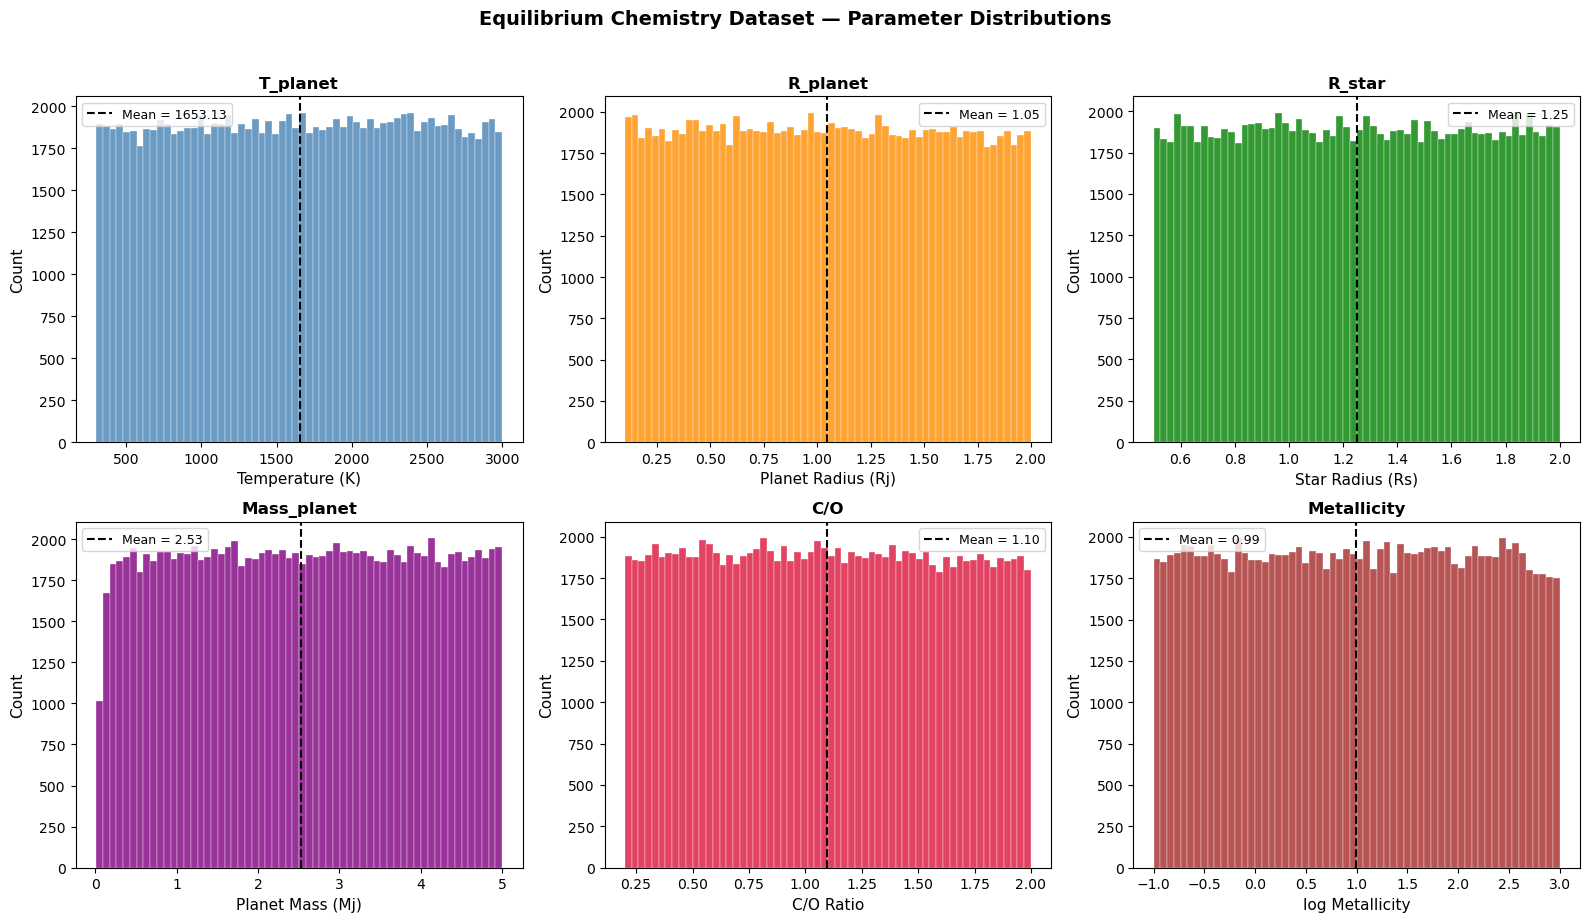

Plot 1 done


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

plot_config = [
    (3, 'Temperature (K)',    'T_planet',    'steelblue'),
    (1, 'Planet Radius (Rj)', 'R_planet',    'darkorange'),
    (0, 'Star Radius (Rs)',   'R_star',      'green'),
    (2, 'Planet Mass (Mj)',   'Mass_planet', 'purple'),
    (5, 'C/O Ratio',          'C/O',         'crimson'),
    (4, 'log Metallicity',    'Metallicity', 'brown'),
]

for ax, (col_idx, xlabel, title, color) in zip(axes, plot_config):
    vals = params_eq[:, col_idx]
    ax.hist(vals, bins=60, color=color,edgecolor='white', alpha=0.8,linewidth=0.3)
    ax.axvline(vals.mean(), color='black',linestyle='--', linewidth=1.5,label=f'Mean = {vals.mean():.2f}')
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(title, fontsize=12,fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle('Equilibrium Chemistry Dataset — ''Parameter Distributions',fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('diag_plot1_param_distributions.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 1 done")

In [5]:
np.random.seed(99)
sample_idx = np.random.choice(len(params_eq),10, replace=False)
atm_list   = []
param_list = []

print("Regenerating 10 atmospheres...")
for idx in sample_idx:
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = \
        params_eq[idx]

    R_p = Rp_Rj * R_J
    M_p = Mp_Mj * M_J
    g_p = (sc.G * M_p) / (R_p ** 2)

    planet = create_planet('p', R_p,gravity=g_p, T_eq=T)
    model  = define_model('m', bulk_species,param_species,PT_profile='isotherm',X_profile='chem_eq')
    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atm = make_atmosphere(planet, model, P,10.0, R_p,PT_params, X_params,chemistry_grid=chemistry_grid)
    atm_list.append(atm)
    param_list.append(params_eq[idx])

print(f"Done. {len(atm_list)} atmospheres ready.")

Regenerating 10 atmospheres...
Done. 10 atmospheres ready.


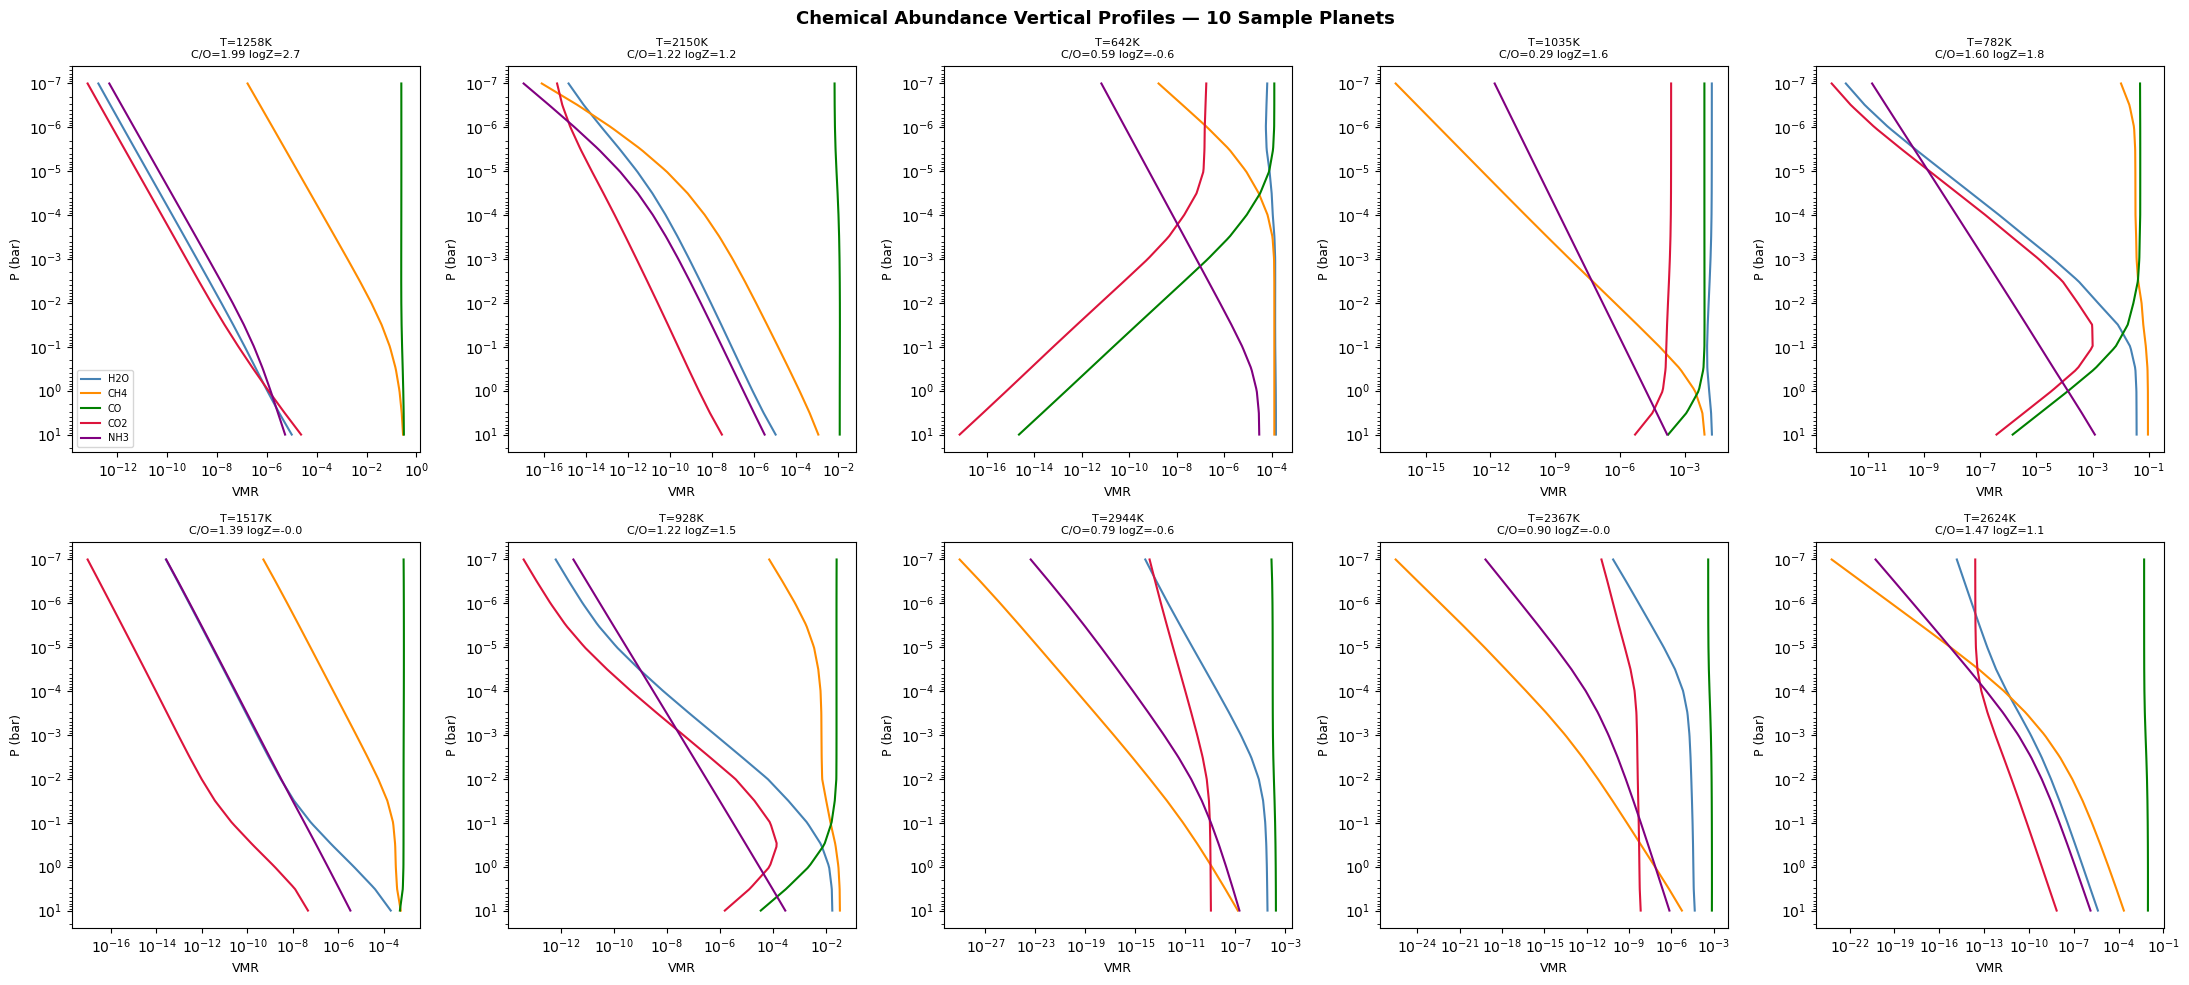

Plot 2 done


In [6]:
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

for planet_idx in range(10):
    row = planet_idx // 5
    col = planet_idx  % 5
    ax  = axes[row][col]

    atm = atm_list[planet_idx]
    par = param_list[planet_idx]

    for mol, mol_idx in zip(mol_names, mol_indices):
        vmr = atm['X'][mol_idx, :, 0, 0]
        vmr = np.where(vmr <= 0, 1e-30, vmr)

        ax.plot(vmr, P,color=mol_colors[mol],label=mol,linewidth=1.5)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.invert_yaxis()
    ax.set_xlabel('VMR', fontsize=9)
    ax.set_ylabel('P (bar)', fontsize=9)
    ax.set_title(f'T={par[3]:.0f}K\n'f'C/O={par[5]:.2f} logZ={par[4]:.1f}',fontsize=8)
    if planet_idx == 0:
        ax.legend(fontsize=7, loc='lower left')

plt.suptitle('Chemical Abundance Vertical Profiles'' — 10 Sample Planets',fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot2_vmr_profiles.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 2 done")

In [8]:
# Find pressure layer closest to 100 mbar
P_target = 0.1
P_idx    = np.argmin(np.abs(P - P_target))
print(f"Using layer {P_idx}: P = {P[P_idx]:.4f} bar")

# Use 10,000 planet subsample for speed
N_sample    = 10000
np.random.seed(42)
sample_idx3 = np.random.choice(len(params_eq),N_sample,replace=False)

vmr_at_100mbar = {mol: [] for mol in mol_names}

print(f"Extracting VMRs at 100 mbar "f"for {N_sample} planets...")

for count, idx in enumerate(sample_idx3):
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = \
        params_eq[idx]

    R_p = Rp_Rj * R_J
    M_p = Mp_Mj * M_J
    g_p = (sc.G * M_p) / (R_p ** 2)

    planet = create_planet('p', R_p, gravity=g_p, T_eq=T)
    model  = define_model('m', bulk_species, param_species, PT_profile='isotherm', X_profile='chem_eq')
    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atm = make_atmosphere(planet, model, P, 0.0, R_p, PT_params, X_params, chemistry_grid=chemistry_grid)

    # THE FIX — use integer index not molecule name string
    for mol, mol_idx in zip(mol_names, mol_indices):
        vmr_val = atm['X'][mol_idx, P_idx, 0, 0]
        vmr_at_100mbar[mol].append(float(vmr_val))

    if count % 2000 == 0:
        print(f"  {count}/{N_sample}")

# Convert lists to arrays
for mol in mol_names:
    vmr_at_100mbar[mol] = np.array(vmr_at_100mbar[mol])

print("Extraction complete.")
for mol in mol_names:
    vals = vmr_at_100mbar[mol]
    print(f"{mol}: min={vals.min():.2e} "f"max={vals.max():.2e} "f"mean={vals.mean():.2e}")

Using layer 25: P = 0.0955 bar
Extracting VMRs at 100 mbar for 10000 planets...
  0/10000
  2000/10000
  4000/10000
  6000/10000
  8000/10000
Extraction complete.
H2O: min=2.05e-16 max=3.61e-01 mean=1.15e-02
CH4: min=3.15e-14 max=5.29e-01 mean=1.60e-02
CO: min=3.61e-31 max=3.98e-01 mean=3.85e-02
CO2: min=1.85e-30 max=1.97e-01 mean=1.73e-03
NH3: min=1.32e-17 max=4.06e-02 mean=1.79e-04


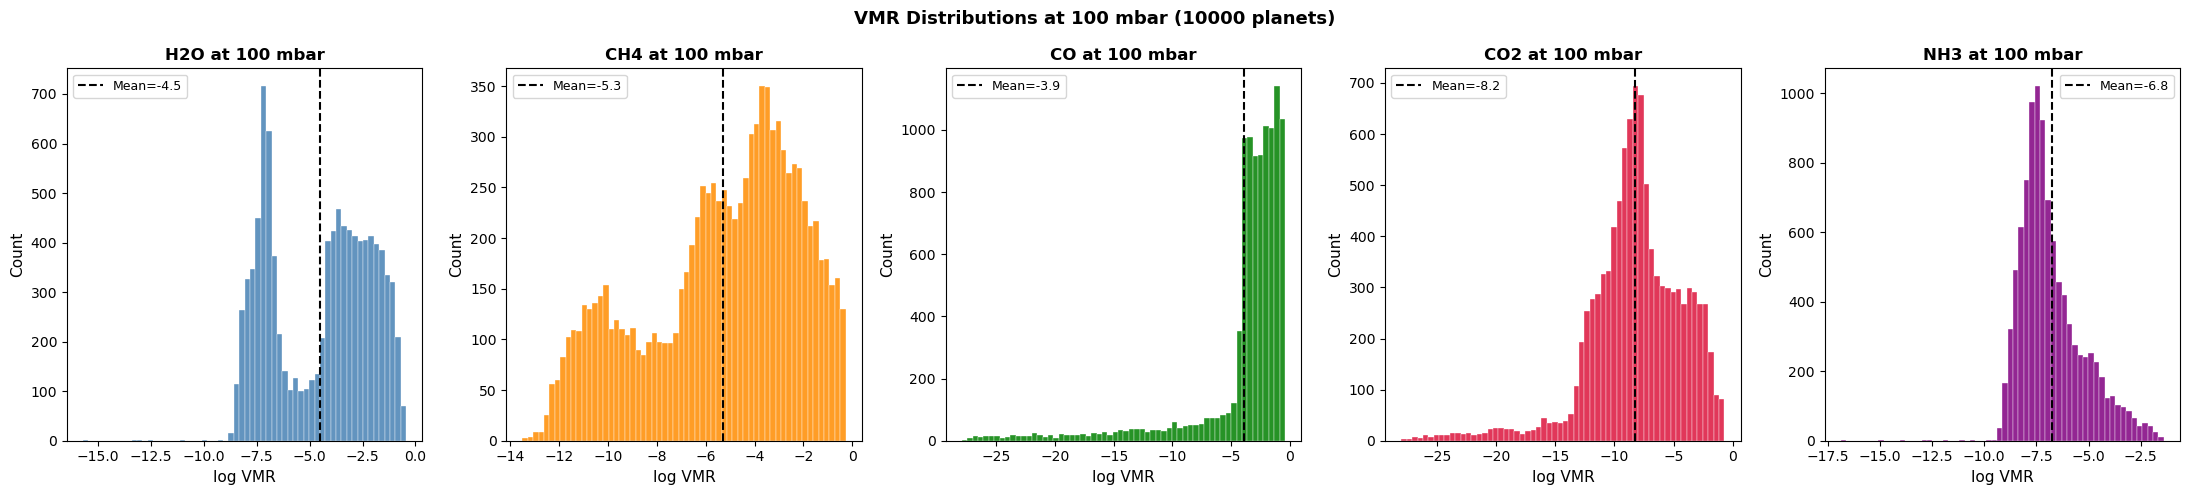

Plot 3 done


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, mol in zip(axes, mol_names):
    raw  = vmr_at_100mbar[mol]
    raw  = np.where(raw <= 0, 1e-30, raw)
    vals = np.log10(raw)
    vals = vals[vals > -28]   # remove placeholder zeros

    ax.hist(vals, bins=60,color=mol_colors[mol],edgecolor='white',alpha=0.85, linewidth=0.3)
    ax.axvline(vals.mean(), color='black',   linestyle='--', linewidth=1.5,   label=f'Mean={vals.mean():.1f}')
    ax.set_xlabel('log VMR', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(f'{mol} at 100 mbar',     fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle(f'VMR Distributions at 100 mbar ' f'({N_sample} planets)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot3_vmr_histograms.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 3 done")

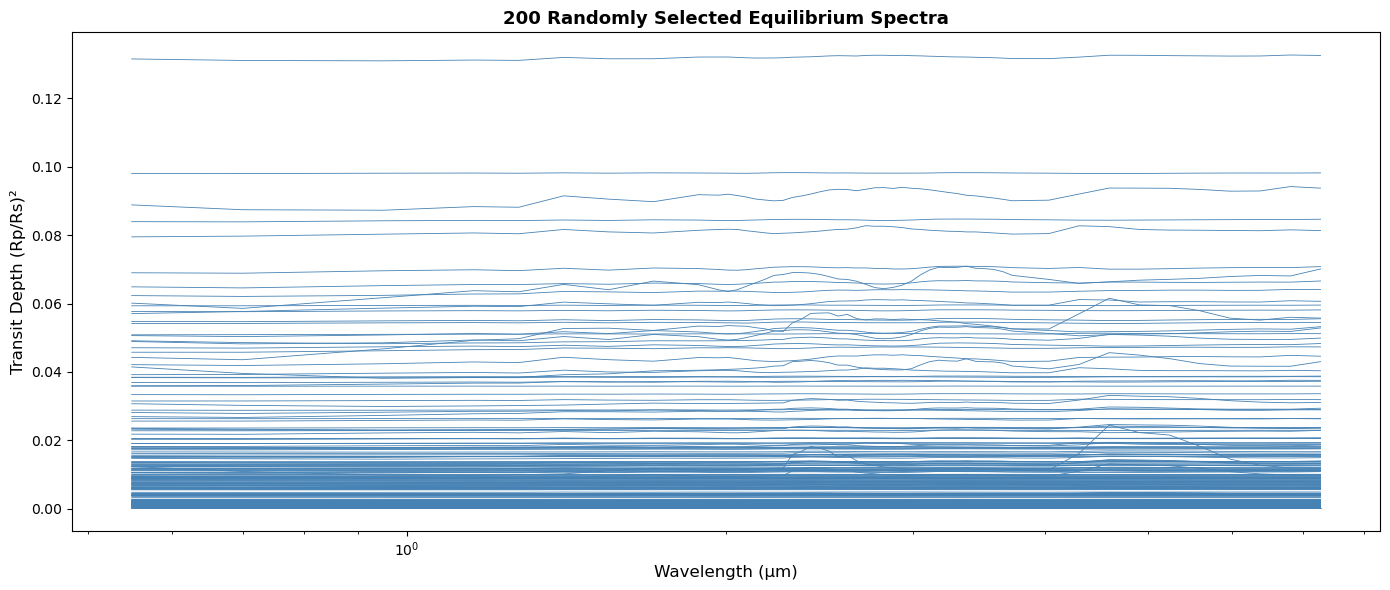

Plot 4 done


In [23]:
# ── Plot 4 — 200 raw spectra ──────────────────
np.random.seed(7)
idx_200 = np.random.choice(len(spectra_eq),200, replace=False)

fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    ax.plot(wl_binned, spectra_eq[i],alpha=1, linewidth=0.6,color='steelblue')
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth (Rp/Rs)²', fontsize=12)
ax.set_title('200 Randomly Selected Equilibrium Spectra', fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot4_200_spectra.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 4 done")

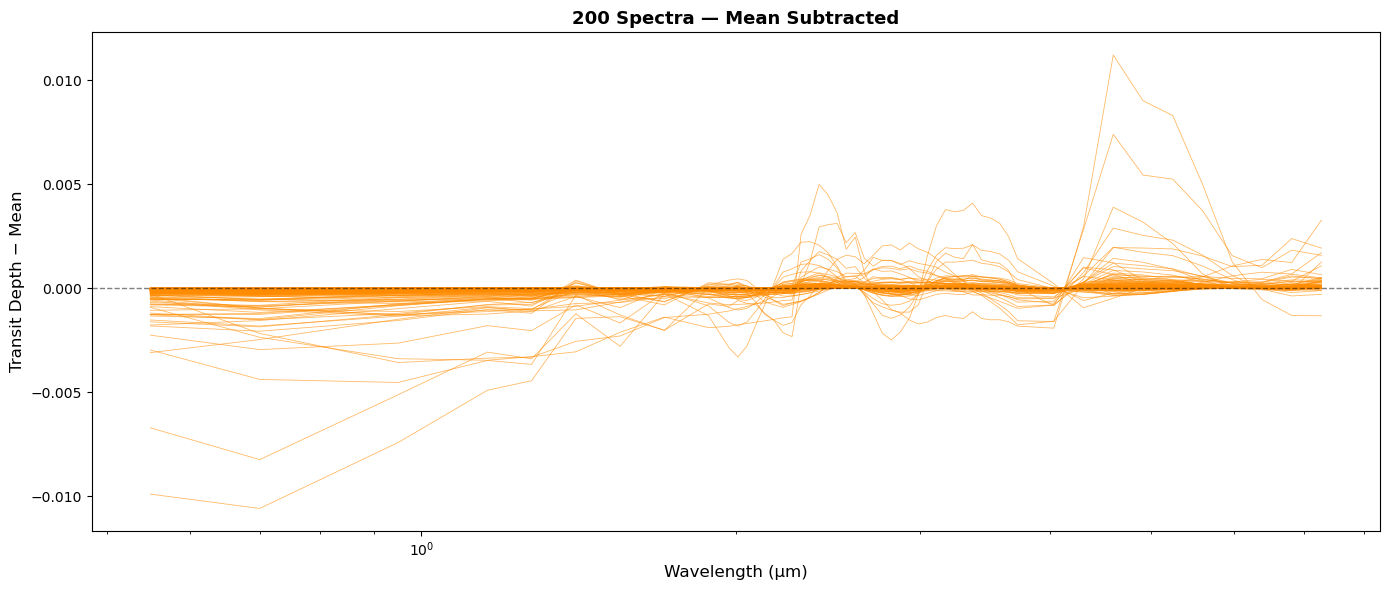

Plot 5 done


In [20]:
# ── Plot 5 — mean subtracted ──────────────────
fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    spec = spectra_eq[i]
    ax.plot(wl_binned, spec - spec.mean(),alpha=0.6, linewidth=0.6,color='darkorange')
ax.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth − Mean', fontsize=12)
ax.set_title('200 Spectra — Mean Subtracted', fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot5_mean_centred.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 5 done")

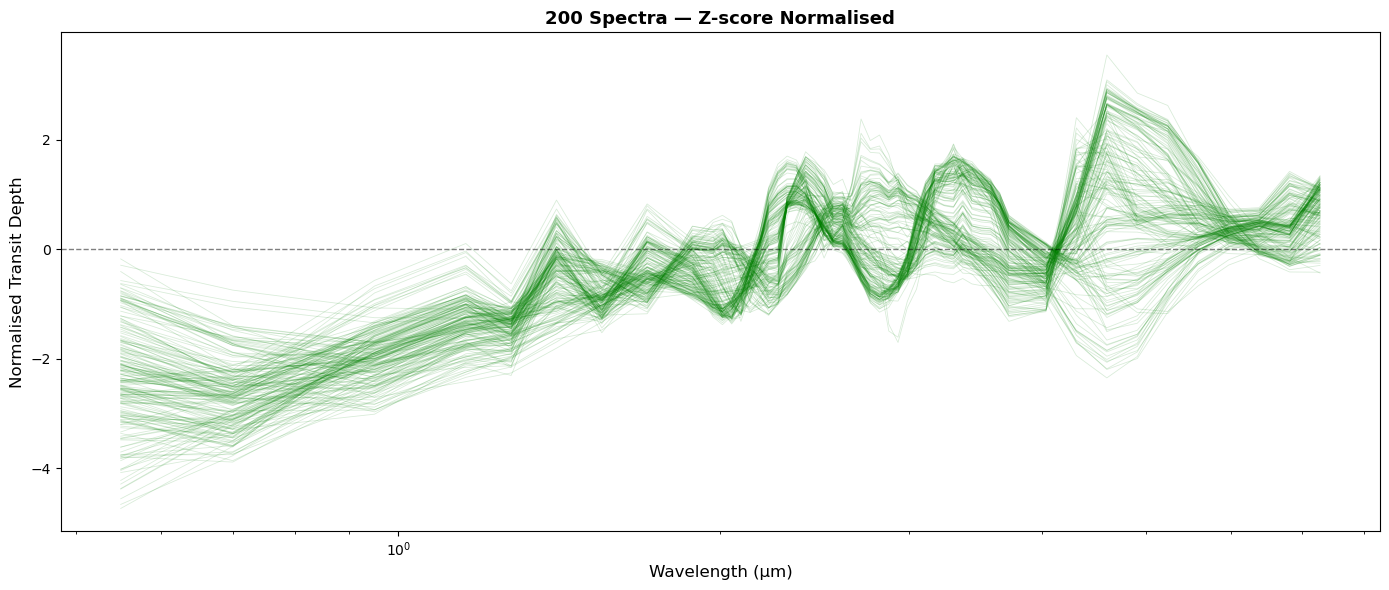

Plot 6 done


In [17]:
# ── Plot 6 — z-score normalised ───────────────
fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    spec = spectra_eq[i]
    std  = spec.std()
    if std > 0:
        spec_norm = (spec - spec.mean()) / std
        ax.plot(wl_binned, spec_norm,alpha=0.15, linewidth=0.6,color='green')
ax.axhline(0, color='black', linewidth=1,linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Normalised Transit Depth',fontsize=12)
ax.set_title('200 Spectra — Z-score Normalised',fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot6_zscore_spectra.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 6 done")

Total spectra : 113176
Spectra with depth>1  : 0
Percentage    : 0.000%


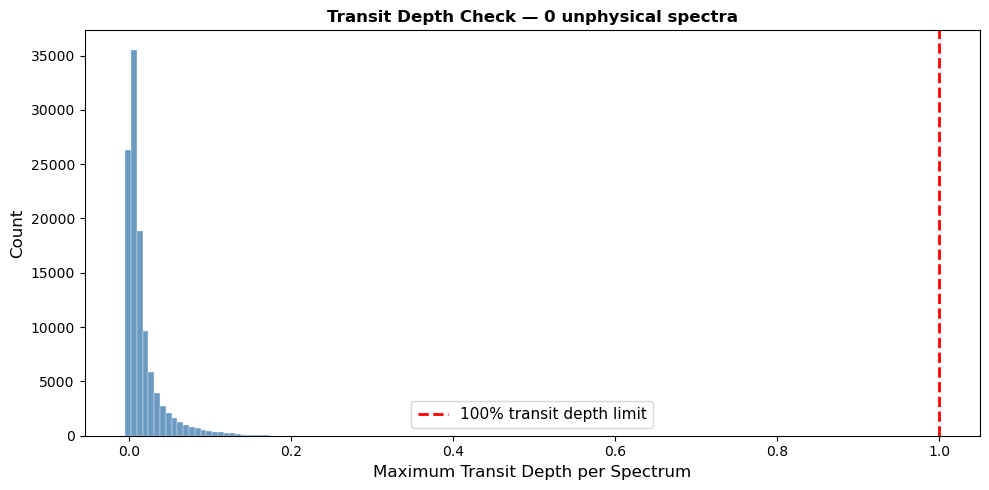

Plot 7 done — 0 bad spectra
All spectra physically valid.


In [18]:
max_depths = spectra_eq.max(axis=1)
bad_mask   = max_depths > 1.0
n_bad      = bad_mask.sum()

print(f"Total spectra : {len(spectra_eq)}")
print(f"Spectra with depth>1  : {n_bad}")
print(f"Percentage    : "f"{n_bad/len(spectra_eq)*100:.3f}%")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_depths, bins=100,color='steelblue', edgecolor='white',alpha=0.8, linewidth=0.3)
ax.axvline(1.0, color='red', linewidth=2,   linestyle='--',   label='100% transit depth limit')
ax.set_xlabel('Maximum Transit Depth per Spectrum',      fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title(f'Transit Depth Check — '     f'{n_bad} unphysical spectra',     fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('diag_plot7_depth_check.png',    dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot 7 done — {n_bad} bad spectra")

if n_bad > 0:
    spectra_clean = spectra_eq[~bad_mask]
    params_clean  = params_eq[~bad_mask]
    np.save('eq_chemistry_spectra_clean.npy',    spectra_clean)
    np.save('eq_chemistry_params_clean.npy',    params_clean)
    print(f"Saved {len(spectra_clean)} clean spectra")
else:
    print("All spectra physically valid.")
    spectra_eq_clean = spectra_eq
    params_eq_clean  = params_eq

In [21]:

vmr_at_100mbar

{'H2O': array([1.51484483e-03, 6.10941070e-05, 9.52876885e-05, ...,
        9.34842428e-03, 6.39202216e-08, 3.15500844e-03]),
 'CH4': array([1.26063604e-03, 7.50079323e-06, 5.82863550e-05, ...,
        1.85879509e-02, 2.61103618e-06, 1.86172466e-02]),
 'CO': array([2.20686683e-07, 1.63475835e-05, 3.06497163e-04, ...,
        2.23750285e-04, 1.21396006e-01, 1.31193377e-02]),
 'CO2': array([3.20781536e-09, 1.23511049e-09, 3.38303694e-08, ...,
        1.42294786e-05, 2.27131769e-09, 1.22751780e-04]),
 'NH3': array([7.14325335e-06, 6.47643576e-08, 1.31408805e-07, ...,
        1.01936953e-05, 1.87156872e-08, 3.76982502e-06])}